# Lab 8


## Setup for SUSY Dataset

Use the SUSY dataset for the rest of this lab. Here is a basic setup. It reads the full file you downloaded in Lab 7 (5 million rows, about 760 MB in memory once loaded). If your computer struggles, read `../Lab.7/SUSY-small.csv` instead (the first 500,000 rows) and divide the sample sizes below by ten.

`RawNames` are the 8 quantities measured directly; `FeatureNames` are the 10 derived from them, which the physicists designed to separate signal from background. You will need both in Exercise 3.

In [1]:
# Our usual libraries...
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import HTML, display
import tabulate
import sklearn

In [3]:
filename="../Lab.7/SUSY.csv"
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", 
          "l_2_phi", "MET", 
          "MET_phi", "MET_rel", "axial_MET",
          "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=[v for v in VarNames[1:] if v not in RawNames]
df = pd.read_csv(filename, dtype='float64', names=VarNames)

## Scikit-Learn

[Scikit-learn](https://scikit-learn.org) is a rich python library for data science, including machine learning. For example, we can build a Fisher Discriminant (aka Linear Discriminant Analysis, or LDA). 

### Exercise 1: Install Scikit-Learn

`scikit-learn` is in the course `requirements.txt`, so it should already be in your environment: check that `import sklearn` works. If it doesn't, follow the [Installation Instructions](https://scikit-learn.org/stable/install.html).

### Exercise 2: Read About Classifiers

#### Part a
Scikit-learn offers an impressively comprehensive list of machine learning algorithms. Browse through [scikit-learn's documentation](https://scikit-learn.org/stable/index.html). You'll note the algorithms are organized into classification, regression, clustering, dimensionality reduction, model selection, and preprocessing. Browse through the list of [classification algorithms](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning). 

#### Part b
Note scikit-learn's documentation is rather comprehensive. The documentation on [linear models](https://scikit-learn.org/stable/modules/linear_model.html) shows how classification problems are setup. Read about the first few methods and try to comprehend the example codes. Skim the rest of the document.

#### Part c
Read through the [LDA Documentation](https://scikit-learn.org/stable/modules/lda_qda.html).


### Exercise 3: Training a Classifier

Let's repeat what we did by hand in the previous lab (Lab 7, Exercise 8) using scikit-learn. We'll use an LDA classifier, which we can instantiate as follows:

In [4]:
# from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
import sklearn.discriminant_analysis as DA
Fisher=DA.LinearDiscriminantAnalysis()

As discussed in the lecture, to properly formulate our problem, we'll have to:

* Define the inputs (X) vs outputs (Y)
* Designate training vs testing samples (in order to get an unbiased assessment of the performance of machine learning algorithms)

For example, here we'll use 4M events for training and the remainder for testing.

In [5]:
N_Train=4000000

Train_Sample=df[:N_Train]
Test_Sample=df[N_Train:]

X_Train=Train_Sample[VarNames[1:]]
y_Train=Train_Sample["signal"]

X_Test=Test_Sample[VarNames[1:]]
y_Test=Test_Sample["signal"]

Test_sig=Test_Sample[Test_Sample.signal==1]
Test_bkg=Test_Sample[Test_Sample.signal==0]


In [6]:
print(X_Train.shape)
print(y_Train.shape)

print(X_Test.shape)
print(y_Test.shape)

(4000000, 18)
(4000000,)
(1000000, 18)
(1000000,)


We can train the classifier as follows:

In [7]:
Fisher.fit(X_Train,y_Train)

,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide <array_api>` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None
Name,Type,Value
"classes_ classes_: array-like of shape (n_classes,)Unique class labels.","ndarray[float64](2,)","[0.,1.]"
"coef_ coef_: ndarray of shape (n_features,) or (n_classes, n_features)Weight vector(s).","ndarray[float64](1, 18)","[[ 1.11,-0. ,-0. ,..., 0.86,-0.04, 2.58]]"
"explained_variance_ratio_ explained_variance_ratio_: ndarray of shape (n_components,)Percentage of variance explained by each of the selected components.If ``n_components`` is not set then all components are stored and thesum of explained variances is equal to 1.0. Only available when eigenor svd solver is used.","ndarray[float64](1,)",[1.]


We can plot the output, comparing signal and background:

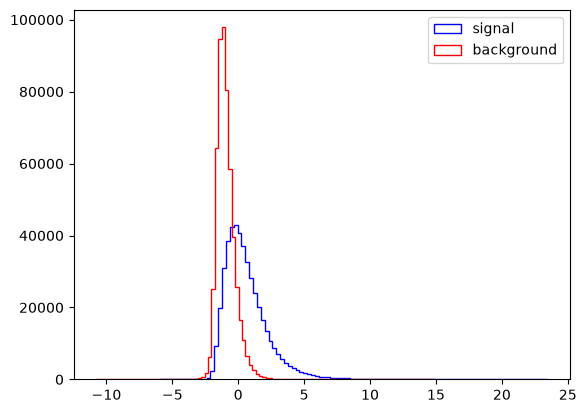

In [8]:
plt.figure()
plt.hist(Fisher.decision_function(Test_sig[VarNames[1:]]),bins=100,histtype="step", color="blue", label="signal",stacked=True)
plt.hist(Fisher.decision_function(Test_bkg[VarNames[1:]]),bins=100,histtype="step", color="red", label="background",stacked=True)
plt.legend(loc='upper right')
plt.show()

In [9]:
test_scores = Fisher.decision_function(X_Test)
print(test_scores[:5])

[-0.97507639 -1.24082161  2.01882632 -0.0478659  -0.62395445]


In [10]:
#Comparing the prediction with actual labels
print("Predicted: ", Fisher.predict(X_Test.iloc[:5]))
print("Actual: ", y_Test.iloc[:5].to_numpy())

Predicted:  [0. 0. 1. 0. 0.]
Actual:  [1. 0. 1. 1. 0.]


#### Part a

Compare the ROC curves computed on the test and on the training samples, in a single plot. Do you see a bias? (Use `Fisher.decision_function` on each sample, and `roc_curve` as in Exercise 5.)

In [11]:
from sklearn.metrics import roc_curve, auc

train_scores = Fisher.decision_function(X_Train)
test_scores = Fisher.decision_function(X_Test)

fpr_train, tpr_train, thresholds_train = roc_curve(
    y_Train, train_scores
)

fpr_test, tpr_test, thresholds_test = roc_curve(
    y_Test, test_scores
)
 
#calculating each curve's area
auc_train = auc(fpr_train, tpr_train)
auc_test = auc(fpr_test, tpr_test)

print("Training AUC: ", auc_train)
print("Test AUC: ", auc_test)




Training AUC:  0.8361729591588447
Test AUC:  0.8364009731285001


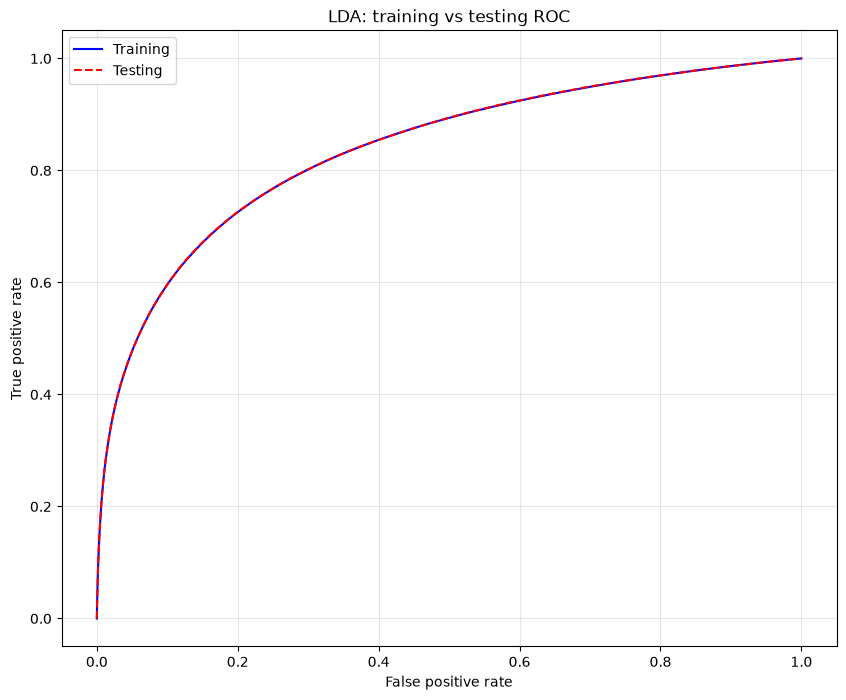

In [12]:
#plotting both curves
plt.figure(figsize = (10, 8))

plt.plot(fpr_train, tpr_train, color = "blue", label = "Training")
plt.plot(fpr_test, tpr_test, color = "red", linestyle = "--", label = "Testing") 

#we basically wants LOW FPR and HIGH TPR which lets to put towards upper left corner
plt.xlabel("False positive rate") #background mistakenly identified as signal
plt.ylabel("True positive rate") #correctly identifies the signal
plt.title("LDA: training vs testing ROC")
plt.legend(loc = "best")
plt.grid(alpha = 0.3)
plt.show()

From the plot, the training and test ROC curves nearly overlap. Training AUC is 0.83617 and test AUC is 0.83640 which shows very similar performance on both samples. Also, there is no noticeable training-test gap which could suggests overfitting. The slighly higher test AUC could be due to sampling variation.

#### Part b

Train three Fisher discriminants, using as input (1) only the raw quantities (`RawNames`), (2) only the derived features (`FeatureNames`), and (3) all 18. Compare their ROC curves, computed on the test sample, in a single plot. Which inputs carry the separation?

In [13]:
#this is a raw-feature model
raw_model = DA.LinearDiscriminantAnalysis()

raw_model.fit(Train_Sample[RawNames], y_Train)

# Calculate a signal/background score for each test event using the raw features.
raw_scores = raw_model.decision_function(Test_Sample[RawNames])

#calculating the ROC and AUC
fpr_raw, tpr_raw, thresholds_raw = roc_curve(y_Test, raw_scores)
auc_raw = auc(fpr_raw, tpr_raw)

print("Raw feature test AUC: ", auc_raw)

Raw feature test AUC:  0.8329941371242162


In [14]:
#this is for engineered features
engineered_model = DA.LinearDiscriminantAnalysis()

engineered_model.fit(Train_Sample[FeatureNames], y_Train)

# Calculate a signal/background score for each test event using the engineered features.
engineered_scores = engineered_model.decision_function(Test_Sample[FeatureNames])

#calculating ROC and AUC
fpr_engineered, tpr_engineered, thresholds_engineered = roc_curve(y_Test, engineered_scores)
auc_engineered = auc(fpr_engineered, tpr_engineered)

print("Engineered features test AUC: ", auc_engineered)



Engineered features test AUC:  0.8231809038576909


In [15]:
#this is for all 18 features
all_model = DA.LinearDiscriminantAnalysis()

all_model.fit(Train_Sample[VarNames[1:]], y_Train)

# Calculate a signal/background score for each test event using all 18 features.
all_scores = all_model.decision_function(Test_Sample[VarNames[1:]])

#calculating ROC and AUC
fpr_all, tpr_all, thresholds_all = roc_curve(y_Test, all_scores)
auc_all = auc(fpr_all, tpr_all)

print("ALl features test AUC: ", auc_all)


ALl features test AUC:  0.8364009731285001


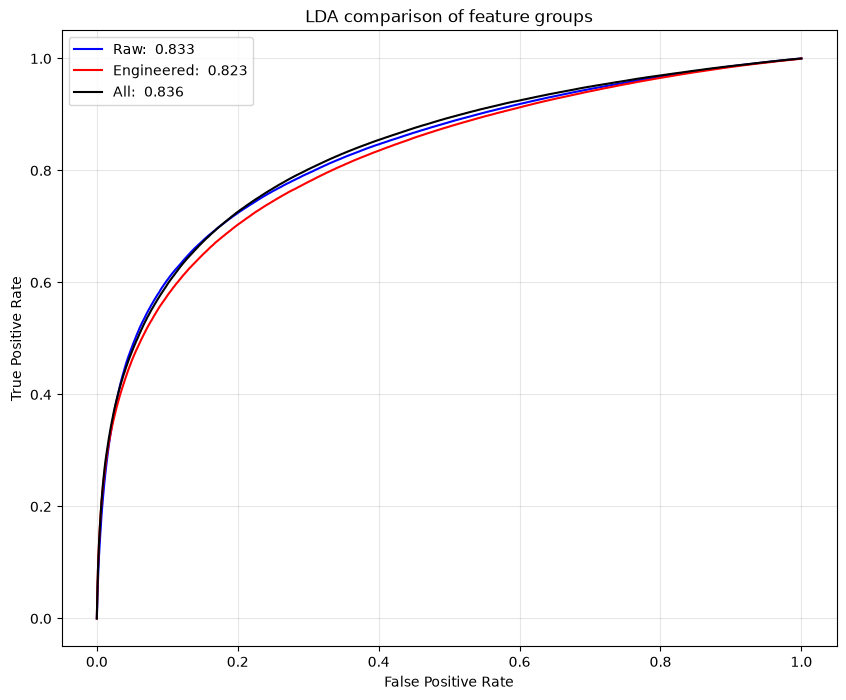

In [16]:
plt.figure(figsize = (10, 8))

plt.plot(fpr_raw, tpr_raw, color = "blue", label = f"Raw: {auc_raw : .3f}")
plt.plot(fpr_engineered, tpr_engineered, color = "red", label = f"Engineered: {auc_engineered : .3f}")
plt.plot(fpr_all, tpr_all, color = "black", label = f"All: {auc_all : .3f}")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("LDA comparison of feature groups")
plt.legend(loc = "best")
plt.grid(alpha = 0.3)
plt.show()

From the AUC curve, it's seen that all features performs best with highest AUC of 0.836 followed by raw which is 0.833 and engineered with 0.823. Most of the separation has already been provided by raw measurements while adding engineered features gives a small improvement of about 0.003 in AUC. This shows that engineered features though it provides useful information, it not quite efficient here.

### Exercise 4: Comparing Techniques

#### Part a
Select 3 different classifiers from the techniques listed [here](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning) to compare. Note that you can use the multi-layer perceptron to build a deep network, though training may be prohibitively slow. So avoid this technique.

#### Part b

Write a function that takes an instantiated classifier and performs the comparison from Exercise 3b. Use the function on each of the classifiers you chose in part a.

#### Part c

Use the best method from part b to compute the maximal significance $\sigma_S= \frac{N_S}{\sqrt{N_S+N_B}}$ for the four scenarios in Lab 7 (Exercise 5.3), choosing the cut on the classifier's output that maximizes it.

In [17]:
#part a(Using all 18 features)
from sklearn.tree import DecisionTreeClassifier

#max_depth = 5 allows at most 5 splits along a path, min_samples_left means requires at least that no. of training events in each leaf
tree_model = DecisionTreeClassifier(max_depth = 5, min_samples_leaf = 100, random_state = 42)

tree_model.fit(X_Train, y_Train)

#calculating probabilities for the scores for ROC
probabilities = tree_model.predict_proba(X_Test)

print(tree_model.classes_)
print(probabilities[:5])

[0. 1.]
[[0.65518749 0.34481251]
 [0.84246206 0.15753794]
 [0.22695578 0.77304422]
 [0.03666515 0.96333485]
 [0.65518749 0.34481251]]


In [18]:
#for the ROC we need the probability of signal which is in index-1 column
tree_probabilities = tree_model.predict_proba(X_Test)
tree_scores = tree_probabilities[:,1] #select all rows from 1 indexed column

fpr_tree, tpr_tree, thresholds_tree = roc_curve(y_Test, tree_scores)
auc_tree = auc(fpr_tree, tpr_tree)

print("Decision tree test AUC: ", auc_tree)

Decision tree test AUC:  0.8410795300512595


In [19]:
# Logistic Regression
from sklearn.pipeline import make_pipeline #pipeline module that combines several processing steps into one object in correct order
from sklearn.preprocessing import StandardScaler #for scaling the numerical features for standarize features
from sklearn.linear_model import LogisticRegression #for learning classification rule

logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter = 1000) #allows upto 1000 optimization iterations
)

#training
logistic_model.fit(X_Train, y_Train)

logistic_probabilities = logistic_model.predict_proba(X_Test)
logistic_scores = logistic_probabilities[:,1]

#calculating ROC and AUC
fpr_logistic, tpr_logistic, thresholds_logistic = roc_curve(y_Test, logistic_scores)
auc_logistic = auc(fpr_logistic, tpr_logistic)

print("Logistic Regression test AUC: ", auc_logistic)

Logistic Regression test AUC:  0.8582326861875805


In [20]:
#histogram gradient boosting
# A single decision tree makes predictions using a sequence of questions. Gradient boosting builds multiple trees sequentially, 
# with each new tree trained to reduce errors in the current combined prediction.
from sklearn.ensemble import HistGradientBoostingClassifier

boost_model = HistGradientBoostingClassifier(
    max_iter = 100,
    learning_rate = 0.1,
    max_leaf_nodes = 15,
    random_state = 42
)

#training the model
boost_model.fit(X_Train, y_Train)

boost_probabilities = boost_model.predict_proba(X_Test)
boost_scores = boost_probabilities[:,1]

#calculating ROC and AUC
fpr_boost, tpr_boost, thresholds_boost = roc_curve(y_Test, boost_scores)
auc_boost = auc(fpr_boost, tpr_boost)

print("Histogram Gradient Boosting test AUC: ", auc_boost)

Histogram Gradient Boosting test AUC:  0.8744141248260419


In [21]:
#Part b
from sklearn.base import clone

def compare_features(classifier, title):
    feature_groups = {
        "Raw" : RawNames,
        "Engineered" : FeatureNames,
        "All" : VarNames[1:]
    }
    results = {}
    plt.figure(figsize = (8,6))

    for name, columns in feature_groups.items():
        model = clone(classifier)

        #training
        model.fit(Train_Sample[columns], y_Train)

        #finding probabilities
        probabilities = model.predict_proba(Test_Sample[columns])

        probability_scores = probabilities[:,1]

        #calculating ROC and AUC
        fpr_model, tpr_model, thresholds_model = roc_curve(y_Test, probability_scores)
        auc_model = auc(fpr_model, tpr_model)

        #plotting 
        plt.plot(fpr_model, tpr_model, label = f"{name}: AUC={auc_model: 3f}")

        results[name] = {
            "model": model,
            "columns": columns,
            "scores": probability_scores,
            "fpr": fpr_model,
            "tpr": tpr_model,
            "thresholds": thresholds_model,
            "auc": auc_model
        }
        print(f"{name} test AUC: {auc_model: .6f}")

    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(title)
    plt.legend()
    plt.show()

    return results

Raw test AUC:  0.836738
Engineered test AUC:  0.820844
All test AUC:  0.841080


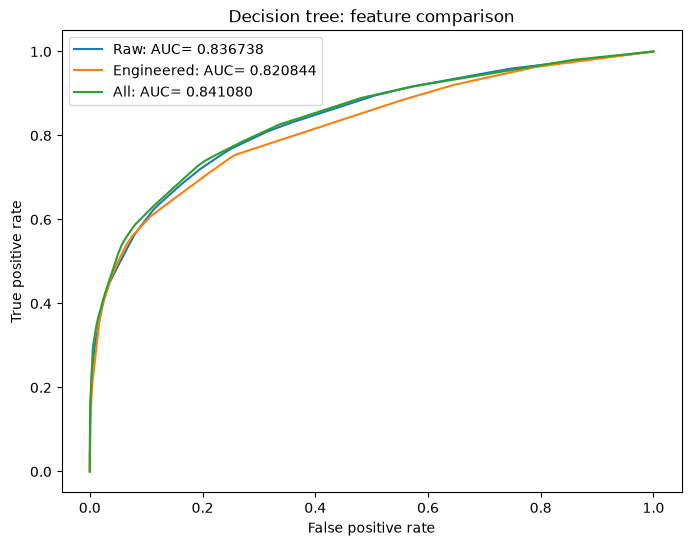

In [22]:
tree_results = compare_features(tree_model, "Decision tree: feature comparison")


Raw test AUC:  0.831427
Engineered test AUC:  0.833797
All test AUC:  0.858233


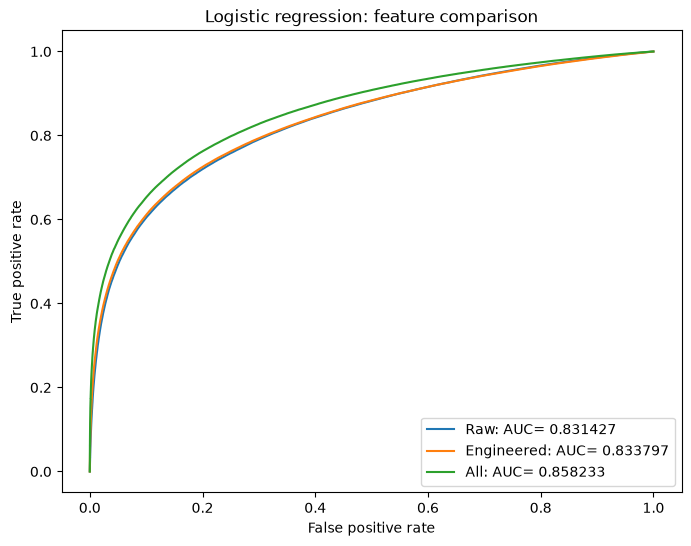

In [26]:
logistic_results = compare_features(logistic_model, "Logistic regression: feature comparison")


Raw test AUC:  0.858146
Engineered test AUC:  0.861545
All test AUC:  0.874414


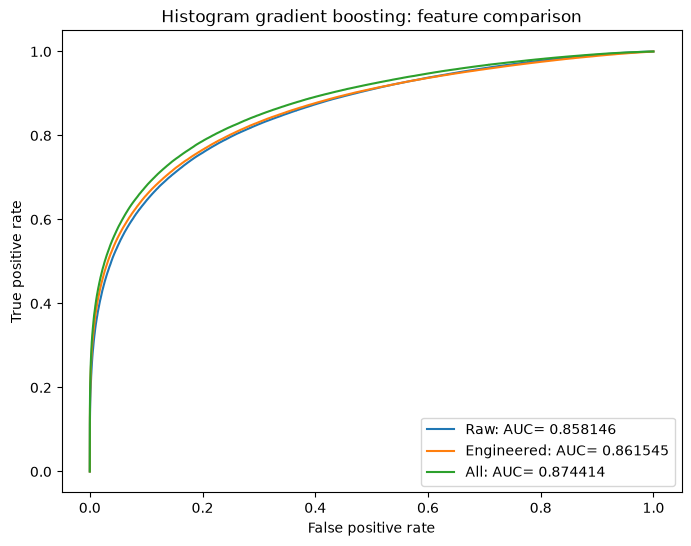

In [34]:
boost_results = compare_features(boost_model, "Histogram gradient boosting: feature comparison")

As we see, all three classifiers performed best when using all 18 features but Histogram gradient boosting has the highest test AUC of 0.874414. Engineered features alone performed slightly better than raw features for logistic regression and boosting, while decision tree performed better with raw features.

In [38]:
# #Part c

# #getting the saved results from above
# best_result = boost_results["All"]

# fpr = best_result["fpr"]
# tpr = best_result["tpr"]
# thresholds = best_result["thresholds"]

# signal_after = 10 * tpr
# background_after = 100 * fpr

# #Handling the rejection by thresholds
# total_after = signal_after + background_after

# significance = np.zeros_like(total_after)

# valid = total_after > 0
# significance[valid]  = signal_after[valid] / np.sqrt(total_after[valid])

# #finding the best thresholds
# best_index = np.argmax(significance)

# print("Best threshold:", thresholds[best_index])
# print("Maximum significance:", significance[best_index])
# print("Expected signal:", signal_after[best_index])
# print("Expected background:", background_after[best_index])

best_result = boost_results["All"]

fpr = best_result["fpr"]
tpr = best_result["tpr"]
thresholds = best_result["thresholds"]

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

scenario_results = {}

for initial_signal, initial_background in scenarios:
    signal_after = initial_signal * tpr
    background_after = initial_background * fpr

    total_after = signal_after + background_after
    significance = np.zeros_like(total_after)

    valid = total_after > 0
    significance[valid] = (
        signal_after[valid] / np.sqrt(total_after[valid])
    )

    best_index = np.argmax(significance)

    scenario_results[(initial_signal, initial_background)] = {
        "threshold": thresholds[best_index],
        "tpr": tpr[best_index],
        "fpr": fpr[best_index],
        "signal_after": signal_after[best_index],
        "background_after": background_after[best_index],
        "significance": significance[best_index]
    }

    print(f"\nInitial signal: {initial_signal}, background: {initial_background}")
    print("Best threshold:", thresholds[best_index])
    print("Maximum significance:", significance[best_index])
    print("Expected signal:", signal_after[best_index])
    print("Expected background:", background_after[best_index])


Initial signal: 10, background: 100
Best threshold: 0.8126412472905327
Maximum significance: 1.8106867115908616
Expected signal: 4.810282105391798
Expected background: 2.2472760430221848

Initial signal: 100, background: 1000
Best threshold: 0.8126412472905327
Maximum significance: 5.725894137627527
Expected signal: 48.102821053917985
Expected background: 22.47276043022185

Initial signal: 1000, background: 10000
Best threshold: 0.8126412472905327
Maximum significance: 18.106867115908617
Expected signal: 481.02821053917984
Expected background: 224.72760430221848

Initial signal: 10000, background: 100000
Best threshold: 0.8126412472905327
Maximum significance: 57.258941376275274
Expected signal: 4810.282105391798
Expected background: 2247.2760430221847


The optimal threshold was approximately 0.813 for all four scenarios. It retained about 48.1% of signal and 2.25% of background. Since the initial signal-to-background ratio stayed constant, the optimal threshold remained unchanged, while significance increased with the square root of the event counts.

### Exercise 5: Metrics

Scikit-learn provides methods for computing the FPR, TPR, ROC, AUC metrics. For example:

In [ ]:
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(y_Test, Fisher.decision_function(X_Test))

roc_auc = auc(fpr, tpr)

plt.plot(fpr,tpr,color='darkorange',label='ROC curve (area = %0.2f)' % roc_auc)
plt.legend(loc="lower right")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.show()


#### Part a
TPR/FPR/ROC/AUC are one way of assessing the quality of a classifier. Read about [Precision and Recall](https://en.wikipedia.org/wiki/Precision_and_recall), [Accuracy](https://en.wikipedia.org/wiki/Accuracy_and_precision), and [F-score](https://en.wikipedia.org/wiki/F-score).

#### Part b
Look through [model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html#) documentation. Using scikit-learn's tools, compute TPR, FPR, ROC, AUC, Precision, Recall, F1 score, and accuracy for the method you selected in Exercise 4c and each scenario. Make a nice table, which also includes the maximal significance. 


In [39]:
# Part B
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score,
    f1_score, accuracy_score, roc_curve, auc
)

scores = boost_results["All"]["scores"]
actual = np.asarray(y_Test)

results = []

for (initial_signal, initial_background), result in scenario_results.items():
    threshold = result["threshold"]
    predicted = (scores >= threshold).astype(int)

    # Weight the test events to represent this scenario's initial counts
    weights = np.where(
        actual == 1,
        initial_signal / np.sum(actual == 1),
        initial_background / np.sum(actual == 0)
    )

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1], sample_weight=weights
    ).ravel()

    fpr_curve, tpr_curve, _ = roc_curve(
        actual, scores, sample_weight=weights
    )

    results.append({
        "Initial signal": initial_signal,
        "Initial background": initial_background,
        "Threshold": threshold,
        "TPR": tp / (tp + fn),
        "FPR": fp / (fp + tn),
        "AUC": auc(fpr_curve, tpr_curve),
        "Precision": precision_score(
            actual, predicted, sample_weight=weights, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, sample_weight=weights, zero_division=0
        ),
        "F1": f1_score(
            actual, predicted, sample_weight=weights, zero_division=0
        ),
        "Accuracy": accuracy_score(
            actual, predicted, sample_weight=weights
        ),
        "Maximum significance": result["significance"]
    })

results_table = pd.DataFrame(results)
display(results_table.round(4))

,Initial signal,Initial background,Threshold,TPR,FPR,AUC,Precision,Recall,F1,Accuracy,Maximum significance
0,10,100,0.8126,0.481,0.0225,0.8744,0.6816,0.481,0.564,0.9324,1.8107
1,100,1000,0.8126,0.481,0.0225,0.8744,0.6816,0.481,0.564,0.9324,5.7259
2,1000,10000,0.8126,0.481,0.0225,0.8744,0.6816,0.481,0.564,0.9324,18.1069
3,10000,100000,0.8126,0.481,0.0225,0.8744,0.6816,0.481,0.564,0.9324,57.2589


At the selected threshold of 0.8126, the classifier retained 48.1% of signal and accepted 2.25% of background. Precision was 68.16%, F1 was 0.564, and accuracy was 93.24%. These metrics remained unchanged across scenarios because their signal-to-background ratios were identical, while significance increased with the event counts.